
# Task 4: Sentiment Analysis

## Objective
To build machine learning models that classify text sentiment as positive, negative, or neutral.

## Tools Used
- Python
- Pandas
- NumPy
- Scikit-learn
- NLTK
- Matplotlib
- Seaborn
- Jupyter Notebook

## Project Workflow
1. Load and inspect the dataset.
2. Analyze the sentiment class distribution.
3. Clean and preprocess text.
4. Convert text into numerical features using TF-IDF.
5. Train at least two classification models.
6. Evaluate the models using classification metrics and confusion matrices.
7. Visualize sentiment distribution and word clouds.
8. Examine five misclassified examples.
9. Summarize the findings and applications.


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:
train_path = "twitter_training.csv"
validation_path = "twitter_validation.csv"

columns = ["Tweet ID", "Entity", "Sentiment", "Tweet"]

train_df = pd.read_csv(train_path, header=None, names=columns)
validation_df = pd.read_csv(validation_path, header=None, names=columns)

print("Training dataset shape:", train_df.shape)
print("Validation dataset shape:", validation_df.shape)

display(train_df.head())

Training dataset shape: (74682, 4)
Validation dataset shape: (1000, 4)


,Tweet ID,Entity,Sentiment,Tweet
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


In [4]:
print("Column names:")
print(train_df.columns.tolist())

print("\nData types:")
print(train_df.dtypes)

print("\nMissing values:")
display(train_df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", train_df.duplicated().sum())

print("\nSentiment labels:")
print(train_df["Sentiment"].value_counts(dropna=False))

Column names:
['Tweet ID', 'Entity', 'Sentiment', 'Tweet']

Data types:
Tweet ID     int64
Entity         str
Sentiment      str
Tweet          str
dtype: object

Missing values:


,Missing Values
Tweet ID,0
Entity,0
Sentiment,0
Tweet,686



Duplicate rows: 2700

Sentiment labels:
Sentiment
Negative      22542
Positive      20832
Neutral       18318
Irrelevant    12990
Name: count, dtype: int64


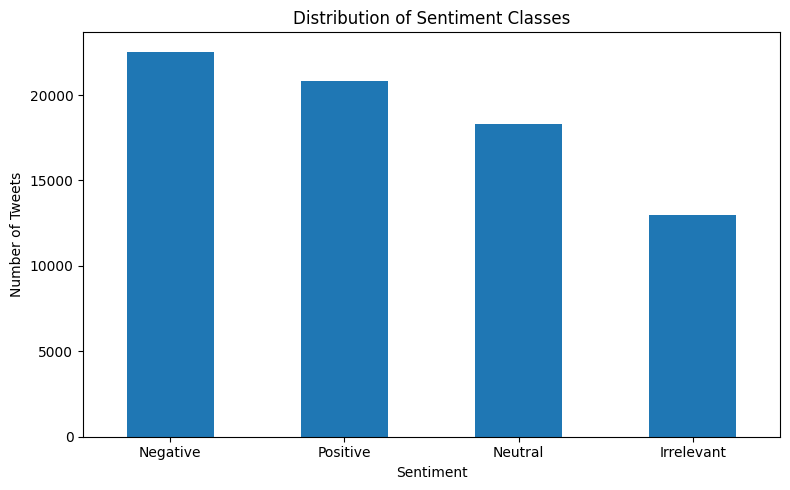

In [5]:
sentiment_counts = train_df["Sentiment"].value_counts()

plt.figure(figsize=(8, 5))
sentiment_counts.plot(kind="bar")
plt.title("Distribution of Sentiment Classes")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
train_df = train_df.dropna(subset=["Sentiment", "Tweet"]).copy()
validation_df = validation_df.dropna(subset=["Sentiment", "Tweet"]).copy()

train_df = train_df.drop_duplicates().copy()
validation_df = validation_df.drop_duplicates().copy()

valid_labels = ["Positive", "Negative", "Neutral", "Irrelevant"]

train_df = train_df[
    train_df["Sentiment"].isin(valid_labels)
].copy()

validation_df = validation_df[
    validation_df["Sentiment"].isin(valid_labels)
].copy()

print("Training rows after cleaning:", len(train_df))
print("Validation rows after cleaning:", len(validation_df))
print("\nTraining sentiment counts:")
print(train_df["Sentiment"].value_counts())

Training rows after cleaning: 71656
Validation rows after cleaning: 1000

Training sentiment counts:
Sentiment
Negative      21698
Positive      19713
Neutral       17708
Irrelevant    12537
Name: count, dtype: int64


## Text Preprocessing

Text preprocessing converts raw tweets into a consistent format for machine learning.

The following steps are used:
1. Convert text to lowercase.
2. Remove URLs.
3. Remove mentions and the hashtag symbol.
4. Remove punctuation and unnecessary special characters.
5. Remove extra whitespace.

We preserve words that carry sentiment information. The TF-IDF vectorizer will handle tokenization and English stopword removal.

In [7]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = text.replace("#", "")
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

train_df["Clean_Tweet"] = train_df["Tweet"].apply(clean_text)
validation_df["Clean_Tweet"] = validation_df["Tweet"].apply(clean_text)

display(train_df[["Tweet", "Clean_Tweet", "Sentiment"]].head(10))

,Tweet,Clean_Tweet,Sentiment
0,im getting on borderlands and i will murder yo...,im getting on borderlands and i will murder yo...,Positive
1,I am coming to the borders and I will kill you...,i am coming to the borders and i will kill you...,Positive
2,im getting on borderlands and i will kill you ...,im getting on borderlands and i will kill you all,Positive
3,im coming on borderlands and i will murder you...,im coming on borderlands and i will murder you...,Positive
4,im getting on borderlands 2 and i will murder ...,im getting on borderlands and i will murder yo...,Positive
5,im getting into borderlands and i can murder y...,im getting into borderlands and i can murder y...,Positive
6,So I spent a few hours making something for fu...,so i spent a few hours making something for fu...,Positive
7,So I spent a couple of hours doing something f...,so i spent a couple of hours doing something f...,Positive
8,So I spent a few hours doing something for fun...,so i spent a few hours doing something for fun...,Positive
9,So I spent a few hours making something for fu...,so i spent a few hours making something for fu...,Positive


## Feature Extraction Using TF-IDF

TF-IDF stands for Term Frequency–Inverse Document Frequency.

- **Term Frequency (TF):** Measures how frequently a word appears in a document.
- **Inverse Document Frequency (IDF):** Reduces the importance of words that occur in many documents.
- **TF-IDF:** Gives higher importance to words that are informative for a particular document.

Machine learning algorithms require numerical input. TF-IDF converts text into numerical feature vectors so that the models can learn patterns associated with different sentiments.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

X_train_text = train_df["Clean_Tweet"]
y_train = train_df["Sentiment"]

X_test_text = validation_df["Clean_Tweet"]
y_test = validation_df["Sentiment"]

tfidf = TfidfVectorizer(
    max_features=20000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2
)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Training feature matrix:", X_train.shape)
print("Testing feature matrix:", X_test.shape)

Training feature matrix: (71656, 20000)
Testing feature matrix: (1000, 20000)


In [10]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(max_iter=1000)

model_lr.fit(X_train, y_train)

pred_lr = model_lr.predict(X_test)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [12]:

from sklearn.naive_bayes import MultinomialNB

model_nb = MultinomialNB()
model_nb.fit(X_train, y_train)

pred_nb = model_nb.predict(X_test)

print("Multinomial Naive Bayes model trained successfully!")


Multinomial Naive Bayes model trained successfully!


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [14]:
from sklearn.metrics import classification_report

print("LOGISTIC REGRESSION — Classification Report")
print(classification_report(y_test, pred_lr, zero_division=0))

print("\nNAIVE BAYES — Classification Report")
print(classification_report(y_test, pred_nb, zero_division=0))

LOGISTIC REGRESSION — Classification Report
              precision    recall  f1-score   support

  Irrelevant       0.90      0.85      0.87       172
    Negative       0.88      0.94      0.91       266
     Neutral       0.94      0.90      0.92       285
    Positive       0.89      0.90      0.89       277

    accuracy                           0.90      1000
   macro avg       0.90      0.90      0.90      1000
weighted avg       0.90      0.90      0.90      1000


NAIVE BAYES — Classification Report
              precision    recall  f1-score   support

  Irrelevant       0.93      0.69      0.79       172
    Negative       0.72      0.87      0.79       266
     Neutral       0.87      0.71      0.78       285
    Positive       0.78      0.90      0.84       277

    accuracy                           0.80      1000
   macro avg       0.83      0.79      0.80      1000
weighted avg       0.82      0.80      0.80      1000



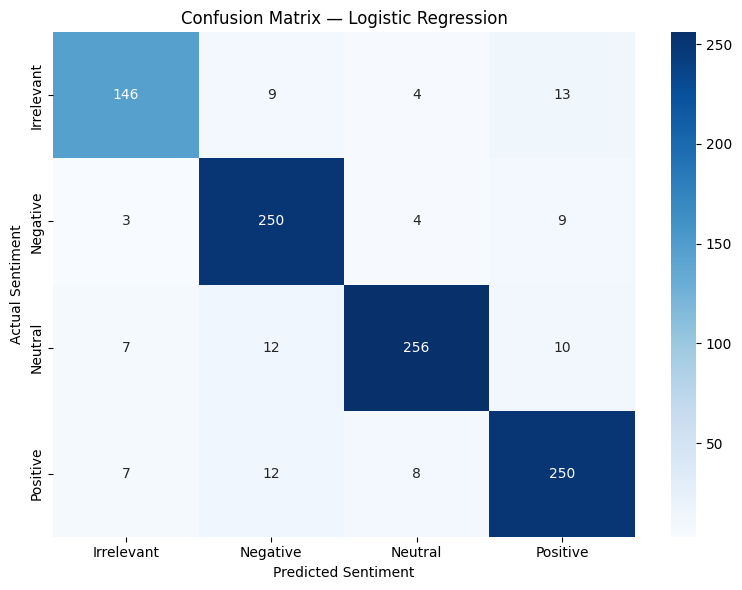

In [15]:
from sklearn.metrics import confusion_matrix

labels = sorted(y_test.unique())

cm_lr = confusion_matrix(y_test, pred_lr, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Confusion Matrix — Logistic Regression")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()
plt.show()

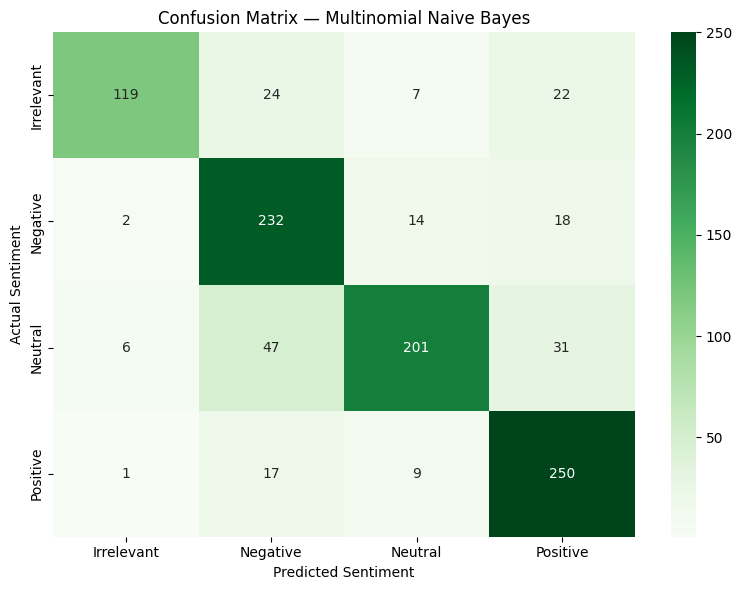

In [16]:
cm_nb = confusion_matrix(y_test, pred_nb, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Confusion Matrix — Multinomial Naive Bayes")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()
plt.show()

In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for model_name, predictions in [
    ("Logistic Regression", pred_lr),
    ("Multinomial Naive Bayes", pred_nb)
]:
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Macro)": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1-score (Macro)": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,Logistic Regression,0.902,0.9017,0.8974,0.8990
1,Multinomial Naive Bayes,0.802,0.8259,0.7930,0.8001


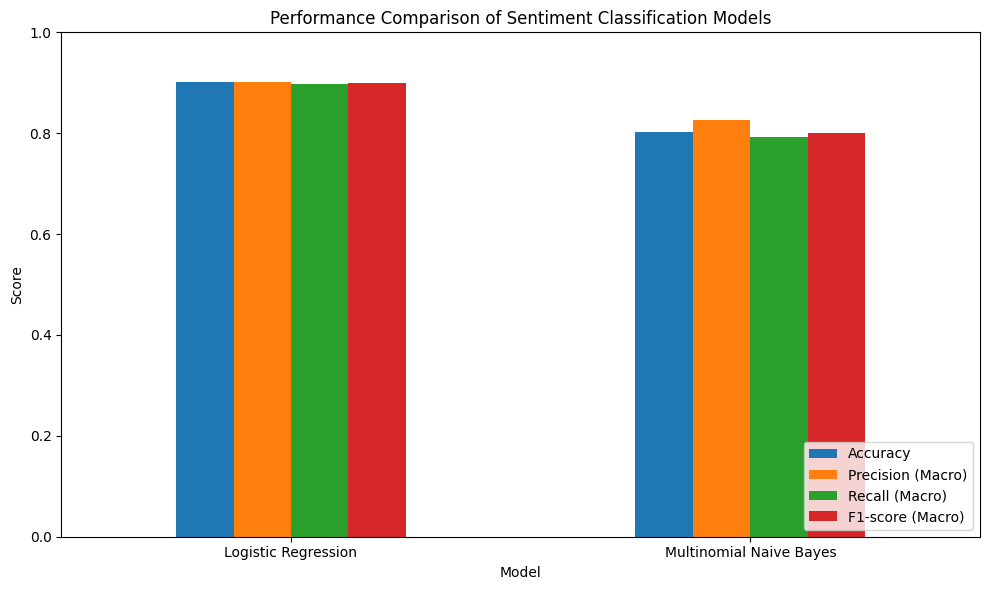

In [19]:
results_plot = results_df.set_index("Model")

results_plot.plot(kind="bar", figsize=(10, 6))
plt.title("Performance Comparison of Sentiment Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

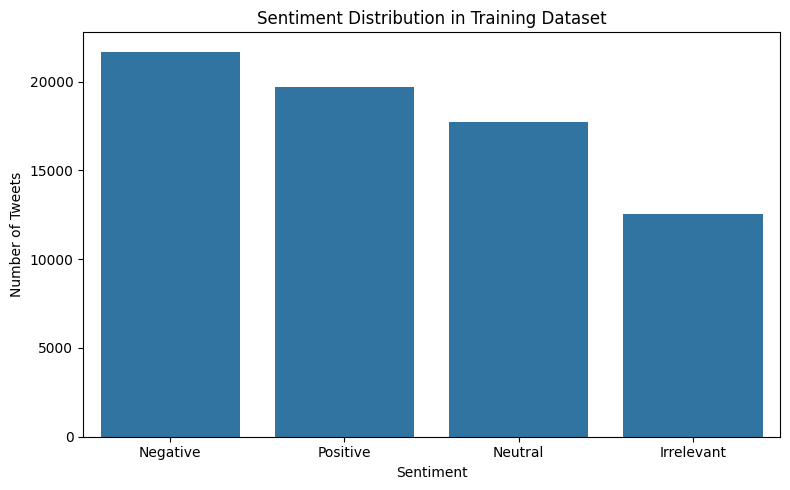

In [20]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x="Sentiment",
    order=train_df["Sentiment"].value_counts().index
)

plt.title("Sentiment Distribution in Training Dataset")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [21]:
%pip install wordcloud

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


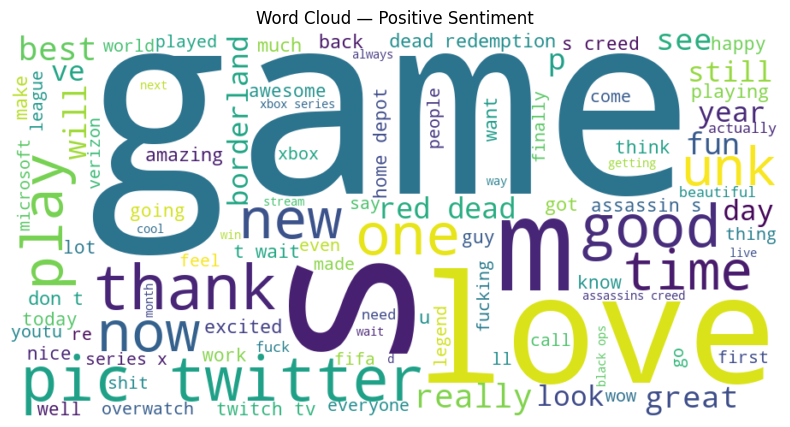

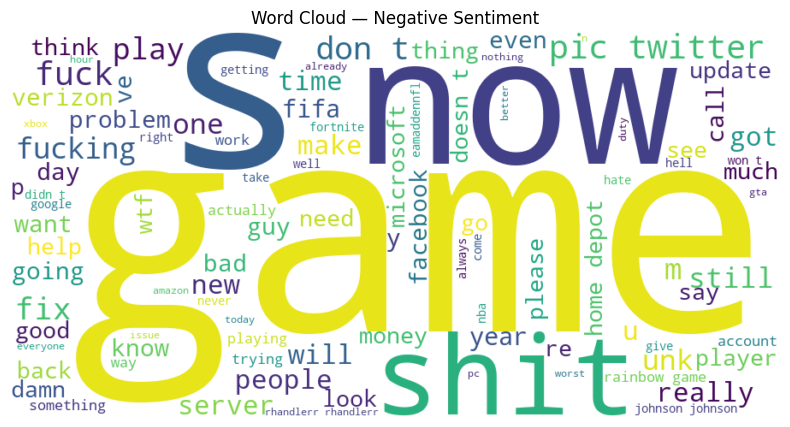

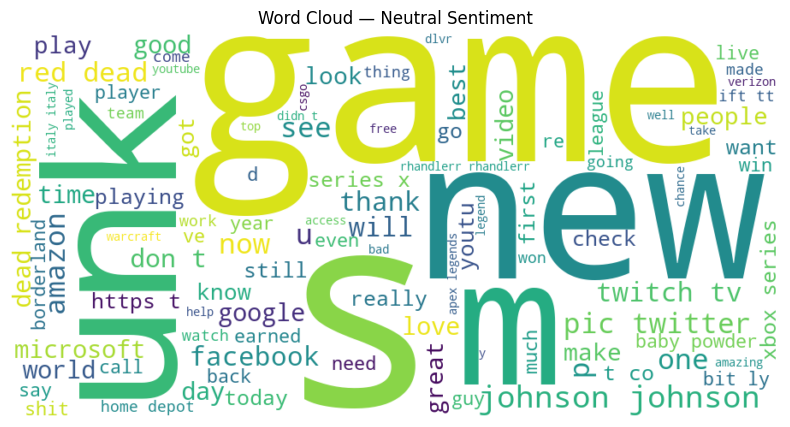

In [22]:
from wordcloud import WordCloud

sentiments_to_plot = ["Positive", "Negative", "Neutral"]

for sentiment in sentiments_to_plot:
    text_data = " ".join(
        train_df.loc[
            train_df["Sentiment"] == sentiment, "Clean_Tweet"
        ].dropna()
    )

    if text_data.strip():
        wordcloud = WordCloud(
            width=900,
            height=450,
            background_color="white",
            max_words=100
        ).generate(text_data)

        plt.figure(figsize=(10, 5))
        plt.imshow(wordcloud, interpolation="bilinear")
        plt.axis("off")
        plt.title(f"Word Cloud — {sentiment} Sentiment")
        plt.show()
    else:
        print(f"No text available for {sentiment} sentiment.")

In [23]:
error_analysis = validation_df[
    ["Tweet", "Clean_Tweet", "Sentiment"]
].copy()

error_analysis["Predicted_Sentiment"] = pred_lr

misclassified = error_analysis[
    error_analysis["Sentiment"] != error_analysis["Predicted_Sentiment"]
]

print("Total misclassified tweets:", len(misclassified))
print("\nFive misclassified examples:")

display(
    misclassified[
        ["Tweet", "Sentiment", "Predicted_Sentiment"]
    ].head(5)
)

Total misclassified tweets: 98

Five misclassified examples:


,Tweet,Sentiment,Predicted_Sentiment
7,"Rocket League, Sea of Thieves or Rainbow Six: ...",Positive,Irrelevant
20,The new @CallofDuty for ps5 is 🔥🔥🔥🔥\nOh God 😭😍,Negative,Positive
42,@PlayCODMobile @M2Games2 i love the call of du...,Neutral,Negative
57,This card is magnificent. \n#nba2kmyteam #sfcr...,Positive,Negative
68,Seems like #Playstation has the marketing deal...,Neutral,Positive


In [24]:
results_df.to_csv("sentiment_model_comparison.csv", index=False)

print("Model comparison results saved successfully!")

Model comparison results saved successfully!


In [25]:
sentiment_predictions = validation_df[
    ["Tweet", "Sentiment"]
].copy()

sentiment_predictions["Predicted_Sentiment"] = pred_lr

sentiment_predictions.to_csv(
    "sentiment_predictions.csv",
    index=False
)

print("Sentiment predictions saved successfully!")

Sentiment predictions saved successfully!


In [26]:
sample_tweets = [
    "I absolutely love this product!",
    "This is the worst experience ever.",
    "The product arrived today."
]

cleaned_tweets = [clean_text(tweet) for tweet in sample_tweets]
tweet_features = tfidf.transform(cleaned_tweets)

predictions = model_lr.predict(tweet_features)

for tweet, sentiment in zip(sample_tweets, predictions):
    print("Tweet:", tweet)
    print("Predicted sentiment:", sentiment)
    print("-" * 50)

Tweet: I absolutely love this product!
Predicted sentiment: Positive
--------------------------------------------------
Tweet: This is the worst experience ever.
Predicted sentiment: Negative
--------------------------------------------------
Tweet: The product arrived today.
Predicted sentiment: Positive
--------------------------------------------------


## Conclusion

This project focuses on sentiment analysis of Twitter data using Natural Language Processing (NLP) and machine learning.

The dataset was inspected and cleaned, and tweet text was preprocessed by converting it to lowercase and removing URLs, mentions, punctuation, and unnecessary characters. TF-IDF was used to convert text into numerical features.

Two classification algorithms, Logistic Regression and Multinomial Naive Bayes, were trained and evaluated using accuracy, precision, recall, F1-score, and confusion matrices.

Sentiment distribution charts and word clouds were created to understand common words and sentiment patterns. Misclassified tweets were also examined to identify possible reasons for incorrect predictions.

The model can support applications such as customer feedback analysis, product review monitoring, and social media opinion analysis. However, sarcasm, slang, and context-dependent expressions can affect prediction accuracy.

In [27]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in this folder:")
for file in sorted(os.listdir(".")):
    print(file)

Current working directory:
C:\Users\sanaa\OneDrive\Desktop\OIBSIP\DataAnalytics-Task4-SentimentAnalysis

Files in this folder:
.ipynb_checkpoints
OIBSIP_Task4_Sentiment_Analysis.ipynb
sentiment_model_comparison.csv
sentiment_predictions.csv
twitter_training.csv
twitter_validation.csv
